<a href="https://colab.research.google.com/github/universe-sm/UCS420-/blob/main/1024160072_A7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [19]:
ROLL_NO = 1024160072          # <-- your full roll number
NAME = "Sania"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [20]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [21]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [22]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160072   Name: Sania   Fingerprint: A69B8B48   Tickets: 14

Ticket_ID                                                                        Ticket_Text
      T01                        The laptop keeps disconnecting. I have tried several times!
      T02                                    The projector keeps disconnecting. Please help.
      T03                                     Re-installing didn't help; log-in still fails!
      T04                         The printer stopped responding. I don't know what changed.
      T05  I couldn't connect to the MATLAB after restarting the system. Can you check this?
      T06   I reinstalled the Python while uploading the file. It works on another computer.
      T07                     The student portal failed to open. I have tried several times!
      T08                    The WiFi keeps asking for login. The same problem occurs again.
      T09                                        I can't login and I didn't change any

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [23]:
# Your code
rows = []
all_tokens = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    all_tokens += r["tokens"]
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punct": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique": len(set(r["tokens"])),
        "Final": len(r["final"]),
    })

res = pd.DataFrame(rows)
total = res.drop(columns="Ticket_ID").sum()
total["Unique"] = len(set(all_tokens))   # unique across ALL tickets, not a sum
total["Ticket_ID"] = "TOTAL"
res = pd.concat([res, total.to_frame().T], ignore_index=True)
print(res.to_string(index=False))

final_all = []
for text in df["Ticket_Text"]:
    final_all += process_ticket(text)["final"]
print(sorted(set(t for t in final_all if "'" in t or t in ("ca", "wo", "ai"))))

Ticket_ID Sentences Tokens Punct Stopwords Unique Final
      T01         2     11     2         3     11     6
      T02         2      8     2         1      7     5
      T03         1      9     2         1      9     6
      T04         2     12     2         4     11     6
      T05         2     17     2         8     16     7
      T06         2     15     2         6     13     7
      T07         2     13     2         4     13     7
      T08         2     13     2         5     11     6
      T09         1     11     1         4      9     6
      T10         1      9     2         2      9     5
      T11         1      5     1         0      5     4
      T12         2     13     2         5     13     6
      T13         2     12     2         5     12     5
      T14         2     17     2         7     15     8
    TOTAL        24    165    26        55     91    84
['ca', "n't"]


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens in my data that are not real words are n't and ca. n't appears 5 times, making it the most frequent final token, and ca also appears in the final tokens. Both come from word_tokenize, which splits contractions into two parts. For example, “can’t” becomes ca + n't, and “didn’t” becomes did + n't. These tickets contain contractions like “can’t”, “didn’t” and “isn’t”, so the fragments appear in the output.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [24]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

def extract(text):
    return {
        "long_words": re.findall(r"\b[A-Za-z]{6,}\b", text),
        "numbers": re.findall(r"\d+(?:[.,]\d+)*", text),
        "capitalized": re.findall(r"\b[A-Z][A-Za-z]*\b", text),
        "vowel_words": re.findall(r"\b[aeiouAEIOU][A-Za-z]*\b", text),
    }

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL   = r"(?:https?://|www\.)[\w\-./?=&%#]*\w"
PHONE = r"\+91[\s-]?\d{5}[\s-]?\d{5}|\b\d{4}-\d{3}-\d{4}\b"

def clean(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

for t in df["Ticket_Text"]:
    print(extract(t)); print(clean(t))
for t in TEST_LINES:
    print(extract(t)); print(clean(t))

{'long_words': ['laptop', 'disconnecting', 'several'], 'numbers': [], 'capitalized': ['The', 'I'], 'vowel_words': ['I']}
The laptop keeps disconnecting. I have tried several times!
{'long_words': ['projector', 'disconnecting', 'Please'], 'numbers': [], 'capitalized': ['The', 'Please'], 'vowel_words': []}
The projector keeps disconnecting. Please help.
{'long_words': ['installing'], 'numbers': [], 'capitalized': ['Re'], 'vowel_words': ['installing', 'in']}
Re-installing didn't help; log-in still fails!
{'long_words': ['printer', 'stopped', 'responding', 'changed'], 'numbers': [], 'capitalized': ['The', 'I'], 'vowel_words': ['I']}
The printer stopped responding. I don't know what changed.
{'long_words': ['couldn', 'connect', 'MATLAB', 'restarting', 'system'], 'numbers': [], 'capitalized': ['I', 'MATLAB', 'Can'], 'vowel_words': ['I', 'after']}
I couldn't connect to the MATLAB after restarting the system. Can you check this?
{'long_words': ['reinstalled', 'Python', 'uploading', 'another', 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Of the 30 capitalized words my regex extracted from the tickets, 16 are capitalized only because they begin a sentence (for example “The”, “Please”, “Can”, “It”, “Write”, “Error”, “Email”). Another 10 are the pronoun “I”, which is always capitalized, and only 4 are genuine proper nouns or product names (MATLAB, Python, WiFi, Matlab). So 16 of the 30 (just over half) are capitalized only because they start a sentence, and together with the 10 uses of “I”, 26 of 30 carry no named-entity information. Only 4 are genuine names. A capitalization-based pattern would badly over-count proper nouns unless sentence-initial words are filtered out or checked against position.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [25]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

PATTERN = "|".join([
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+",              # emails
    r"(?:https?://|www\.)[\w\-./?=&%#]*\w",       # URLs
    r"\+91[\s-]?\d{5}[\s-]?\d{5}|\d{4}-\d{3}-\d{4}",  # phones
    r"0[xX][0-9A-Fa-f]+",                         # hex codes like 0x80070005
    r"\d+(?:[.,]\d+)*",                           # numbers, decimals, versions
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*",               # words, hyphens, contractions
    r"[^\w\s]",                                   # any other single punctuation mark
])

_tok = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

for line in TEST_LINES:
    print("mine:", my_tokenize(line))
    print("nltk:", word_tokenize(line))
    print()

diff = 0
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    if my_tokenize(text) != word_tokenize(text):
        diff += 1
        print(tid, "differs")
print(f"{diff} of {len(df)} tickets tokenized differently")

mine: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
nltk: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

mine: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
nltk: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

mine: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
nltk: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']

T03 differs
T04 differs
T05 differs
T09 differs
T10 differs
T14 differs
6 of 14 tic

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 6 of my 14 tickets (T03, T04, T05, T09, T10 and T14) are tokenized differently by my_tokenize and word_tokenize; the other 8 come out identical. The differences come from a few causes:

Contractions: word_tokenize splits them (didn't becomes did + n't, can't becomes ca + n't), while my tokenizer keeps them whole as single tokens.
Special tokens: on the TEST_LINES, word_tokenize breaks emails, URLs and phone numbers into pieces (it.helpdesk, @, thapar.edu; https, :, //lms...; +91, 98765, 43210), while mine keeps each as one token.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [26]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# unique final tokens across all tickets
uniq = set()
for text in df["Ticket_Text"]:
    uniq.update(process_ticket(text)["final"])
uniq = sorted(uniq)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"(ing|ed|es|s)$", min=4)   # my suffix rule
lemma = WordNetLemmatizer()

def wn_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

tags = dict(pos_tag(uniq))

rows = []
for w in uniq:
    row = {
        "Word": w,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp.stem(w),
        "Lemma": lemma.lemmatize(w, wn_pos(tags[w])),
    }
    outs = {row["Porter"], row["Lancaster"], row["Regexp"], row["Lemma"]}
    if len(outs) > 1:
        rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

         Word    Porter     Lancaster     Regexp         Lemma
       access    access        access      acces        access
      another     anoth         anoth    another       another
     anything     anyth         anyth      anyth      anything
       change     chang         chang     change        change
      changed     chang         chang      chang        change
         code      code           cod       code          code
     computer    comput        comput   computer      computer
        error     error            er      error         error
        fails      fail          fail       fail         fails
         file      file           fil       file          file
       mobile     mobil          mobl     mobile        mobile
       occurs     occur           occ      occur         occur
         open      open            op       open          open
       please     pleas         pleas     please        please
       portal    portal          port     portal       

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: Lancaster reduces portal to port, which merges it with an unrelated word, and it cuts error to er and student to stud. Different meanings collapse into the same or meaningless stems because Lancaster strips too aggressively.

Under-stemming: reinstalled and re-installing are forms of the same verb, but they end up with different stems (reinstal vs re-instal under Porter, reinstal vs re-installing under Lancaster). The hyphen blocks the stemmers from treating them as one word, so related forms stay separate. Lemmatizer output (reinstall and re-installing) shows the same gap.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set   Tokens  Unique     TTR
S1       165      91   0.552
S2       139      86   0.619
S3        84      62   0.738
S4        84      59   0.702

Top 10 S1: [('.', 18), ('the', 13), ('i', 10), ("n't", 5), ('!', 4), ('keeps', 3), ('have', 3), ('tried', 3), ('several', 3), ('times', 3)]
Top 10 S3: [("n't", 5), ('keeps', 3), ('tried', 3), ('several', 3), ('times', 3), ('disconnecting', 2), ('help', 2), ('stopped', 2), ('responding', 2), ('matlab', 2)]


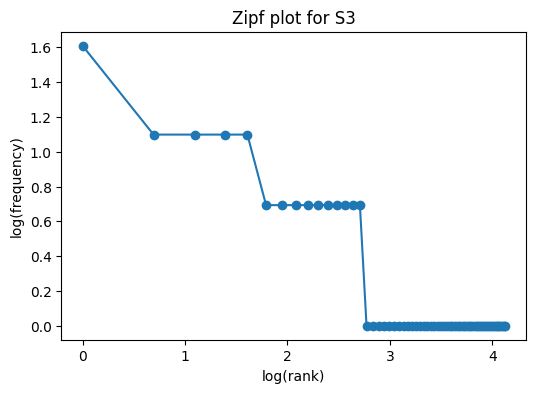


Top 5 bigrams S1: [(('.', 'i'), 6), (('i', 'have'), 3), (('have', 'tried'), 3), (('tried', 'several'), 3), (('several', 'times'), 3)]
Top 5 bigrams S3: [(('tried', 'several'), 3), (('several', 'times'), 3), (('keeps', 'disconnecting'), 2), (('stopped', 'responding'), 2), (('student', 'portal'), 2)]


In [27]:
# Your code
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk import bigrams
from nltk.stem import PorterStemmer

S1, S2, S3 = [], [], []
for text in df["Ticket_Text"]:
    r = process_ticket(text)
    S1 += r["tokens"]
    S2 += [t for t in r["tokens"] if not is_punct(t)]
    S3 += r["final"]

porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

corpora = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}

print(f"{'Set':<4}{'Tokens':>8}{'Unique':>8}{'TTR':>8}")
for name, toks in corpora.items():
    n, u = len(toks), len(set(toks))
    print(f"{name:<4}{n:>8}{u:>8}{u/n:>8.3f}")

print("\nTop 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

# Zipf plot for S3
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in freqs], marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3")
plt.show()

print("\nTop 5 bigrams S1:", Counter(bigrams(S1)).most_common(5))
print("Top 5 bigrams S3:", Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (unique tokens divided by total tokens) rises from 0.552 in S1 to 0.619 in S2 and 0.738 in S3, then falls slightly to 0.702 in S4.

S1 to S2 (removing punctuation): the total drops from 165 to 139 because punctuation marks repeat heavily (. appears 18 times and ! 4 times), but the unique count only falls from 91 to 86, since only a few distinct punctuation types disappear. The total shrinks faster than the unique count, so TTR rises.
S2 to S3 (removing stopwords): the total drops from 139 to 84. Stopwords such as the (13 times) and i (10 times) are highly repetitive, so removing them takes out many tokens but only 24 unique types (86 to 62). TTR rises again, and S3 is left with a more varied vocabulary.
S3 to S4 (Porter stemming): the total stays at 84, because stemming replaces tokens instead of deleting them, but the unique count falls from 62 to 59 as variants merge (for example changed/change into chang, stopped into stop). With the same total and fewer unique types, TTR drops to 0.702.

So TTR increases whenever we remove repetitive tokens, and decreases when stemming merges word forms. A low TTR in S1 reflects how much of the raw text is repeated function words and punctuation.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

*ANSWER*:-
(b) On the line “The state-of-the-art lab isn’t open; log-in at 5.30 p.m. didn’t work.”, word_tokenize splits the contractions (isn't → is, n't; didn't → did, n't), while my tokenizer keeps each as one token because my pattern allows an apostrophe inside a word. They differ the other way on p.m.: word_tokenize keeps it whole, but my tokenizer breaks it into p, ., m, . since it has no abbreviation rule.

(c) Lancaster stems portal to port, which is an unrelated word with a different meaning (over-stemming). It also reduces error to er and student to stud, which are not meaningful words.

(d) For tried, Porter, Lancaster and the regexp stemmer all give tri, which is not a word. The POS-aware lemmatizer returns try, a valid base form that keeps the meaning, because it uses the verb tag and a dictionary instead of just chopping the suffix.
